In [46]:
from sklearn.datasets import load_iris
import matplotlib.pyplot as plt 
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [47]:
import pandas as pd

mall_data = pd.read_csv("Mall_Customers.csv", sep = ";")
df = pd.DataFrame(mall_data)
df

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (0-1)
0,1,Male,19.0,15.0,0.39
1,2,Male,21.0,15.0,0.81
2,2,Male,21.0,15.0,0.81
3,3,NaN,20.0,16.0,0.06
4,4,Female,NaN,16.0,0.77
...,...,...,...,...,...
196,196,Female,35.0,120.0,0.79
197,197,Female,45.0,126.0,0.28
198,198,Male,32.0,126.0,0.74
199,199,Male,32.0,137.0,0.18


In [48]:
cut_df = mall_data[["Annual Income (k$)", "Spending Score (0-1)"]]
cut_df

,Annual Income (k$),Spending Score (0-1)
0,15.0,0.39
1,15.0,0.81
2,15.0,0.81
3,16.0,0.06
4,16.0,0.77
...,...,...
196,120.0,0.79
197,126.0,0.28
198,126.0,0.74
199,137.0,0.18


In [49]:
cut_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 201 entries, 0 to 200
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Annual Income (k$)    197 non-null    float64
 1   Spending Score (0-1)  201 non-null    float64
dtypes: float64(2)
memory usage: 3.3 KB


In [50]:
cut_df.isnull().sum()

Annual Income (k$)      4
Spending Score (0-1)    0
dtype: int64

In [51]:
cut_df = cut_df.dropna()
cut_df.isnull().sum()

Annual Income (k$)      0
Spending Score (0-1)    0
dtype: int64

In [52]:
cut_df.duplicated().sum()

np.int64(5)

In [53]:
cut_df = cut_df.drop_duplicates()
cut_df.duplicated().sum()

np.int64(0)

<Axes: xlabel='Annual Income (k$)', ylabel='Spending Score (0-1)'>

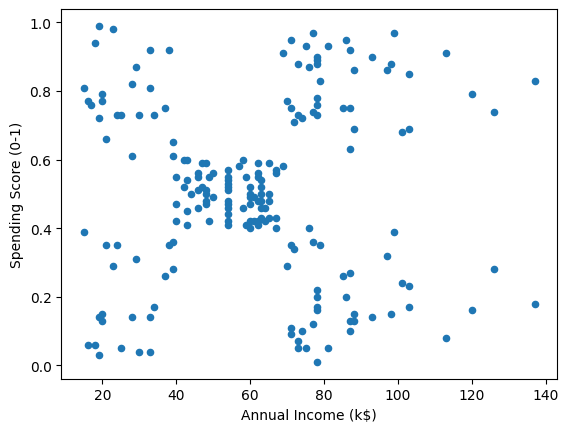

In [54]:
cut_df.plot.scatter("Annual Income (k$)", "Spending Score (0-1)")

In [55]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer

quant_pipeline = Pipeline([
    ('scaler', StandardScaler())
])

df = df.dropna()

In [56]:
df_transformed = quant_pipeline.fit_transform(cut_df)

In [57]:
df_new = pd.DataFrame(df_transformed)

In [58]:
# Function to plot final clusters
def plot_clusters_sklearn(data, labels, clusters):

    # Plot data points, choosing first two features for visualization
    plt.scatter(data.iloc[:, 0], data.iloc[:, 1], c=labels, cmap='viridis', label='Data points')

    # Plot cluster centers, also focusing on the same two features
    plt.scatter(clusters[:, 0], clusters[:, 1], s=200, color='red', marker='X', label='Centers')
    plt.title('Visualizing Clusters with Matplotlib using Mall Customeres Dataset')
    plt.xlabel('Sepal Length (cm)')
    plt.ylabel('Sepal Width (cm)')
    plt.legend()
    plt.grid(True)
    plt.show()

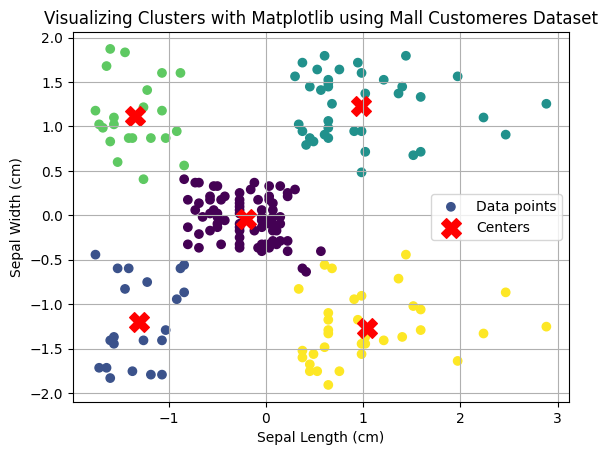

In [62]:
k= 5
# k=3
#k = 5


# Perform K-means clustering and take cluster centers
kmeans_model = KMeans(n_clusters=k, n_init=10)
kmeans_model.fit(df_new)
labels = kmeans_model.labels_
clusters_sklearn = kmeans_model.cluster_centers_

plot_clusters_sklearn(df_new, labels, clusters_sklearn)